In [1]:
import pandas as pd
import numpy as np
from vis.utils_motifs import motif_to_fwords
from collections import Counter
import ast
import matplotlib.pyplot as plt
import torch
import math
from scipy.stats import ttest_rel

In [8]:
# file_name = r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\edge_faithfulness_top0p050_100repeats.csv"
file_name = r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\ablation.csv"
df = pd.read_csv(file_name)
df

,row,class,mode,label,prediction,correct,p_true_class,confidence_drop
0,13,Human,original,0,0,1,0.999578,0.000000
1,13,Human,no_edges,0,0,1,0.999757,-0.000179
2,13,Human,no_features,0,0,1,0.985733,0.013844
3,13,Human,no_edge_weights,0,0,1,0.999992,-0.000414
4,13,Human,no_edges_no_features,0,0,1,0.987142,0.012435
...,...,...,...,...,...,...,...,...
1795,2399,Machine,original,1,1,1,0.999229,0.000000
1796,2399,Machine,no_edges,1,1,1,0.537614,0.461615
1797,2399,Machine,no_features,1,0,0,0.016192,0.983037
1798,2399,Machine,no_edge_weights,1,1,1,0.765215,0.234014


In [9]:
summary = df.groupby(["mode", "class"]).agg(
    n=("row", "size"),
    accuracy=("correct", "mean"),
    predicted_machine=("prediction", "mean"),
    mean_confidence=("p_true_class", "mean")
)

display(summary)

n  accuracy  predicted_machine  \
mode                 class                                       
no_edge_weights      Human    180  1.000000           0.000000   
                     Machine  180  0.911111           0.911111   
no_edges             Human    180  1.000000           0.000000   
                     Machine  180  0.694444           0.694444   
no_edges_no_features Human    180  1.000000           0.000000   
                     Machine  180  0.000000           0.000000   
no_features          Human    180  1.000000           0.000000   
                     Machine  180  0.000000           0.000000   
original             Human    180  1.000000           0.000000   
                     Machine  180  0.988889           0.988889   

                              mean_confidence  
mode                 class                     
no_edge_weights      Human           0.999883  
                     Machine         0.891035  
no_edges             Human           0.998954  
                     Machine         0.675128  
no_edges_no_features Human           0.987142  
                     Machine         0.012858  
no_features          Human           0.984709  
                     Machine         0.014949  
original             Human           0.994277  
                     Machine         0.988604

In [10]:
import numpy as np

df["p_machine"] = np.where(
    df["label"] == 1,
    df["p_true_class"],
    1 - df["p_true_class"]
)

summary = df.groupby(["mode", "class"]).agg(
    accuracy=("correct", "mean"),
    mean_p_machine=("p_machine", "mean"),
    std_p_machine=("p_machine", "std"),
    min_p_machine=("p_machine", "min"),
    max_p_machine=("p_machine", "max")
)

display(summary)

accuracy  mean_p_machine  std_p_machine  \
mode                 class                                              
no_edge_weights      Human    1.000000        0.000117       0.001292   
                     Machine  0.911111        0.891035       0.260017   
no_edges             Human    1.000000        0.001046       0.005765   
                     Machine  0.694444        0.675128       0.335103   
no_edges_no_features Human    1.000000        0.012858       0.000000   
                     Machine  0.000000        0.012858       0.000000   
no_features          Human    1.000000        0.015291       0.001471   
                     Machine  0.000000        0.014949       0.001154   
original             Human    1.000000        0.005723       0.043350   
                     Machine  0.988889        0.988604       0.070723   

                              min_p_machine  max_p_machine  
mode                 class                                  
no_edge_weights      Human         0.000000       0.017226  
                     Machine       0.000090       1.000000  
no_edges             Human         0.000000       0.049288  
                     Machine       0.002031       0.998925  
no_edges_no_features Human         0.012858       0.012858  
                     Machine       0.012858       0.012858  
no_features          Human         0.012924       0.020096  
                     Machine       0.012650       0.019117  
original             Human         0.000000       0.439158  
                     Machine       0.403889       1.000000

### Conclusions:
* When we remove all edges, since we have self loops, every node has a connection to itself, so every node can still transform its own features, even without receiving information from other nodes.
* Node features contain substantial predicitve information (acc ~85%). After removing edges, these is a decrease from 97+ % to ~85%, so edges contribute to the model's predictions.
* Removing node features causes the model to predict everything as human.
* Removing ~20% of edges did not have large influence on the predictions, but if we remove all, accuracy drops, so perhaps the GNN's predictions depend on the graph connections to some extent, but not necessarily on a small number of important edges.
* 

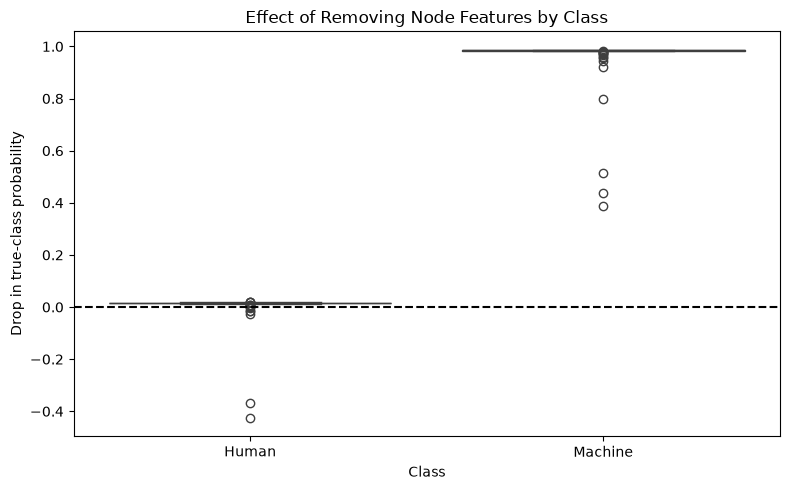

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = df[
    df["mode"] == "no_features"
]

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_plot,
    x="class",
    y="confidence_drop"
)

plt.axhline(0, color="black", linestyle="--")

plt.ylabel("Drop in true-class probability")
plt.xlabel("Class")
plt.title("Effect of Removing Node Features by Class")

plt.tight_layout()
plt.show()

In [15]:
file_abl = r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\expl_attributes_object_abl.csv"
df_abl = pd.read_csv(file_abl)

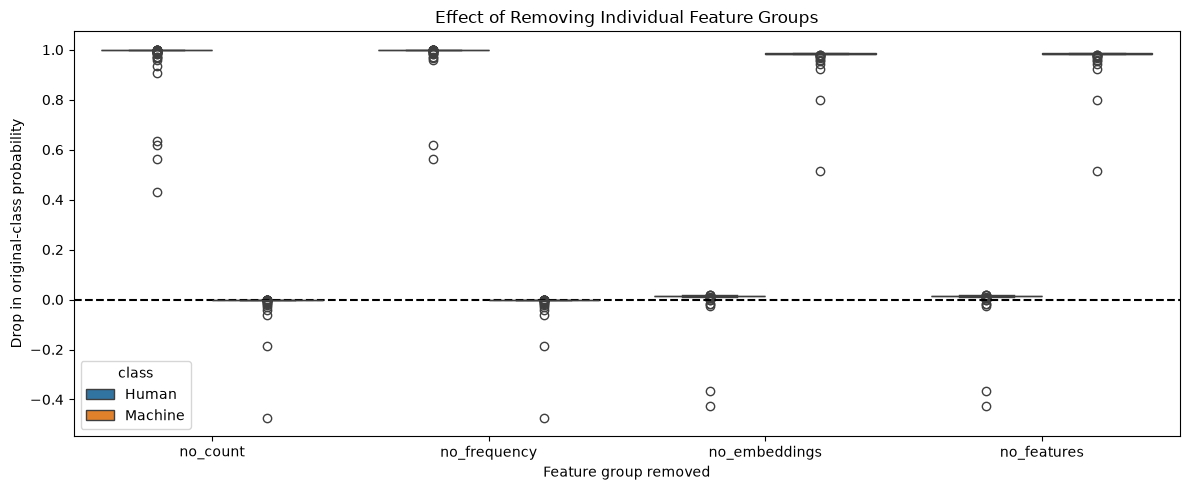

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

modes = [
    "no_count",
    "no_frequency",
    "no_embeddings",
    "no_features",
]

plot_df = df_abl[df_abl["mode"].isin(modes)].copy()

# Only analyze graphs originally classified correctly
correct_rows = df_abl.loc[
    (df_abl["mode"] == "original") &
    (df_abl["correct"] == 1),
    "row"
]

plot_df = plot_df[plot_df["row"].isin(correct_rows)]

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=plot_df,
    x="mode",
    y="confidence_drop",
    hue="class",
    order=modes,
)

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Feature group removed")
plt.ylabel("Drop in original-class probability")
plt.title("Effect of Removing Individual Feature Groups")

plt.tight_layout()
plt.show()

In [17]:
original_preds = (
    df_abl[df_abl["mode"] == "original"]
    [["row", "prediction"]]
    .rename(columns={"prediction": "original_prediction"})
)

df_flips = df_abl.merge(
    original_preds,
    on="row",
)

df_flips["flipped"] = (
    df_flips["prediction"] != df_flips["original_prediction"]
)

flip_summary = (
    df_flips[df_flips["mode"].isin(modes)]
    .groupby(["mode", "class"])["flipped"]
    .mean()
    .reset_index()
)

print(flip_summary)

            mode    class   flipped
0       no_count    Human  0.994444
1       no_count  Machine  0.011111
2  no_embeddings    Human  0.000000
3  no_embeddings  Machine  0.988889
4    no_features    Human  0.000000
5    no_features  Machine  0.988889
6   no_frequency    Human  1.000000
7   no_frequency  Machine  0.011111


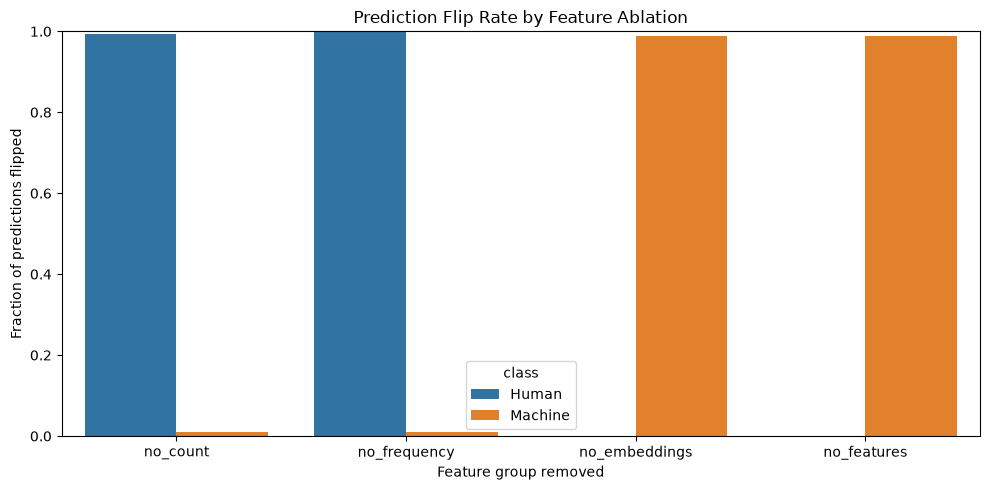

In [19]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=flip_summary,
    x="mode",
    y="flipped",
    hue="class",
    order=modes,
)

plt.ylabel("Fraction of predictions flipped")
plt.xlabel("Feature group removed")
plt.title("Prediction Flip Rate by Feature Ablation")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [20]:
prediction_summary = (
    df_abl[df_abl["mode"].isin(["original"] + modes)]
    .groupby(["mode", "class"])["prediction"]
    .agg(
        fraction_machine="mean",
        n_graphs="count"
    )
    .reset_index()
)

print(prediction_summary)

            mode    class  fraction_machine  n_graphs
0       no_count    Human          0.994444       180
1       no_count  Machine          1.000000       180
2  no_embeddings    Human          0.000000       180
3  no_embeddings  Machine          0.000000       180
4    no_features    Human          0.000000       180
5    no_features  Machine          0.000000       180
6   no_frequency    Human          1.000000       180
7   no_frequency  Machine          1.000000       180
8       original    Human          0.000000       180
9       original  Machine          0.988889       180
